# Week 3 – FFT frequency resolution
Goal: show that Δf = fs/N = 1/T decides whether two close tones (50 Hz and 55 Hz) can be separated.


In [1]:
import numpy as np
import matplotlib.pyplot as plt

fs = 1000  # sampling rate in Hz

def spectrum(duration):
    t = np.arange(0, duration, 1/fs)              # time axis: duration seconds, one point every 1/fs s
    x = np.sin(2*np.pi*50*t) + np.sin(2*np.pi*55*t)  # two tones, 5 Hz apart
    N = len(x)                                    # number of samples
    X = np.fft.rfft(x)                            # FFT (positive frequencies only)
    f = np.fft.rfftfreq(N, 1/fs)                  # frequency of each FFT bin
    amp = 2/N * np.abs(X)                         # scale so a sine of amplitude 1 shows ~1
    return f, amp, N

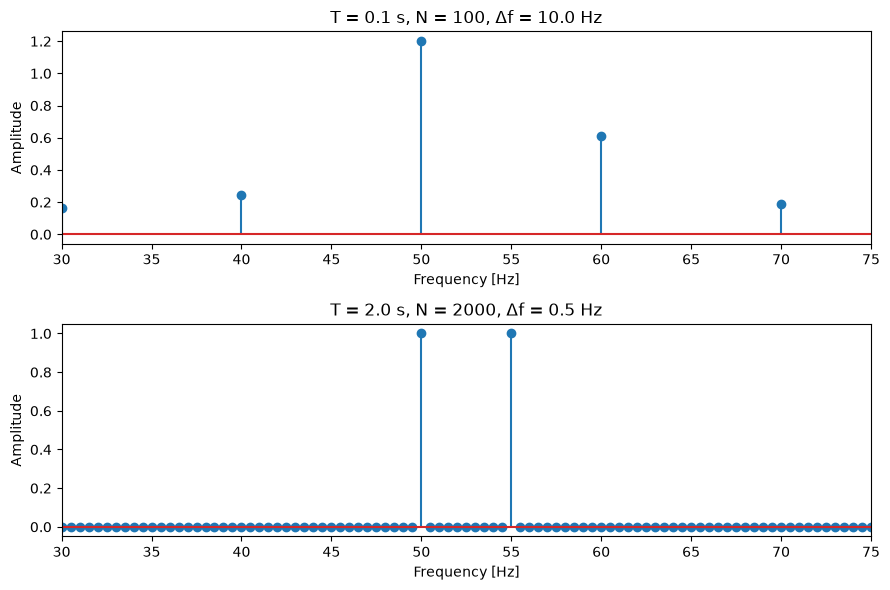

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(9, 6))

for ax, T in zip(axes, [0.1, 2.0]):
    f, amp, N = spectrum(T)
    ax.stem(f, amp)                    # one stick per FFT bin, so you see the bins themselves
    ax.set_xlim(30, 75)                # zoom in around the two tones
    ax.set_title(f"T = {T} s, N = {N}, Δf = {fs/N} Hz")
    ax.set_xlabel("Frequency [Hz]")
    ax.set_ylabel("Amplitude")

plt.tight_layout()
plt.show()

- Δf = fs/N = 1/T, so resolution depends on **how long** you record, not on fs.

in the first plot we can see the signals mixed into one wrong sized peak and then we had leaks in to other into neighbouring bins at 40, 60 ... know as spectral leakage. All this happened beacuse our recording timme was too short and thus we couldn't identfy the two different signals.

In the second plot we can see two distinct peaks at the right height(amplitude) and a valley in between them that drops to zero is a clear sign that we have two differnt signals at 50Hz and 55Hz